# FSDD spoken digit classification

In [92]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import torch
import torch.nn.functional as F
import torchaudio

DATA_DIR = Path("data/free-spoken-digit-dataset/recordings")

## Part 1. Audio preprocessing

In [93]:
SAMPLE_RATE = 8000
NUM_SAMPLES = SAMPLE_RATE  # 1 second
HOP_LENGTH = 80
N_MELS = 40

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE,
    n_fft=256,
    win_length=256,
    hop_length=HOP_LENGTH,
    window_fn=torch.hann_window,
    n_mels=N_MELS,
    f_min=0.0,
    f_max=4000.0,
    power=2.0,
)


def load_waveform(path):
    audio, sr = sf.read(path, dtype="float32")
    assert sr == SAMPLE_RATE, f"{path}: expected {SAMPLE_RATE} Hz, got {sr}"
    waveform = torch.from_numpy(audio)
    # Pad with zeros or truncate to exactly 1 second
    waveform = F.pad(waveform, (0, max(0, NUM_SAMPLES - len(waveform))))
    return waveform[:NUM_SAMPLES]


def log_mel_spectrogram(waveform):
    return torch.log(mel_transform(waveform) + 1e-6)

In [94]:
path = DATA_DIR / "0_jackson_0.wav"
waveform = load_waveform(path)
log_mel = log_mel_spectrogram(waveform)

# With center=True (default), frames = 1 + NUM_SAMPLES // HOP_LENGTH
assert waveform.shape == (NUM_SAMPLES,)
assert log_mel.shape == (N_MELS, 1 + NUM_SAMPLES // HOP_LENGTH)
print("waveform:", tuple(waveform.shape))
print("log-mel: ", tuple(log_mel.shape))

waveform: (8000,)
log-mel:  (40, 101)


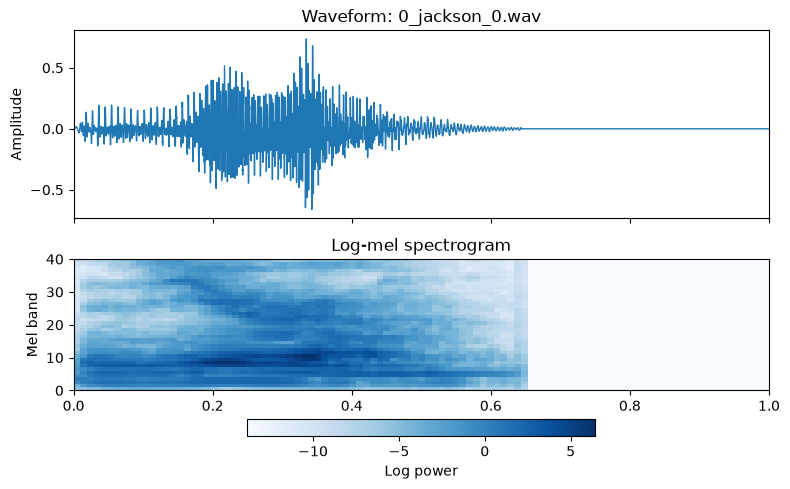

In [95]:
fig, (ax_wave, ax_mel) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)

t = torch.arange(NUM_SAMPLES) / SAMPLE_RATE
ax_wave.plot(t, waveform, linewidth=1)
ax_wave.set_title(f"Waveform: {path.name}")
ax_wave.set_ylabel("Amplitude")

img = ax_mel.imshow(
    log_mel, origin="lower", aspect="auto", cmap="Blues", extent=(0, 1, 0, N_MELS)
)
ax_mel.set_title("Log-mel spectrogram")
ax_mel.set_xlabel("Time (s)")
ax_mel.set_ylabel("Mel band")
fig.colorbar(img, ax=ax_mel, label="Log power", location="bottom", shrink=0.5)

fig.tight_layout()
plt.show()

## Part 2. Classical ML baseline

Features: mean and standard deviation of each mel band over time (80 values), computed two ways:

- **padded**: over the whole 1 s clip, including the zero padding
- **trimmed**: only over the frames that cover the original audio

A third set, **both**, joins the two (160 values).

Split: FSDD's official test set is the recordings with index 0–4. Of the rest, index 5–9 is used for validation and 10–49 for training. All choices are made on the validation set. The test set is used only once, in the final comparison.

In [96]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def mel_stats(log_mel):
    return torch.cat([log_mel.mean(dim=1), log_mel.std(dim=1)])


paths = sorted(DATA_DIR.glob("*.wav"))
# File names are {digit}_{speaker}_{index}.wav
y = np.array([int(p.stem.split("_")[0]) for p in paths])
index = np.array([int(p.stem.split("_")[2]) for p in paths])
is_test = index < 5
is_val = (index >= 5) & (index < 10)
is_train = index >= 10
print(f"train: {is_train.sum()}, val: {is_val.sum()}, test: {is_test.sum()}")

lengths = np.array([sf.info(p).frames for p in paths])
waves = torch.stack([load_waveform(p) for p in paths])
log_mels = log_mel_spectrogram(waves)

# Frames that cover the original audio, before padding
n_frames = 1 + np.minimum(lengths, NUM_SAMPLES) // HOP_LENGTH
X_padded = torch.stack([mel_stats(m) for m in log_mels]).numpy()
X_trimmed = torch.stack([mel_stats(m[:, :n]) for m, n in zip(log_mels, n_frames)]).numpy()
X_both = np.hstack([X_padded, X_trimmed])

train: 2400, val: 300, test: 300


Duration: min 0.14 s, median 0.42 s, max 2.28 s
Truncated (longer than 1 s): 20 of 3000
Average share of the clip that is padding: 56%


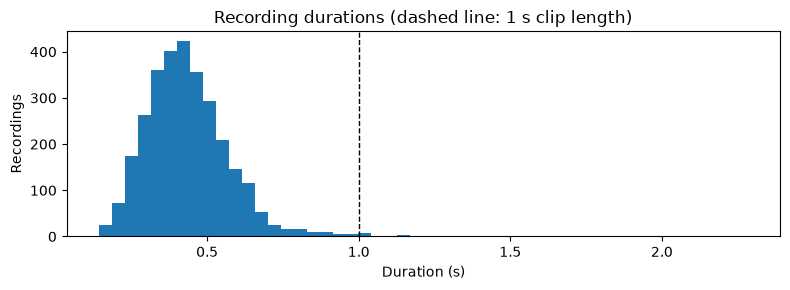

In [97]:
durations = lengths / SAMPLE_RATE
print(f"Duration: min {durations.min():.2f} s, median {np.median(durations):.2f} s, max {durations.max():.2f} s")
print(f"Truncated (longer than 1 s): {(lengths > NUM_SAMPLES).sum()} of {len(lengths)}")
print(f"Average share of the clip that is padding: {np.clip(1 - durations, 0, None).mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(durations, bins=50)
ax.axvline(NUM_SAMPLES / SAMPLE_RATE, color="black", linestyle="--", linewidth=1)
ax.set_title("Recording durations (dashed line: 1 s clip length)")
ax.set_xlabel("Duration (s)")
ax.set_ylabel("Recordings")
fig.tight_layout()
plt.show()

In [98]:
def scores(y_true, y_pred):
    return accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average="macro")


feature_sets = {"padded": X_padded, "trimmed": X_trimmed, "both": X_both}
logregs = {}

print(f"{'Features':<10}{'Dim':>5}{'Train acc':>11}{'Val acc':>9}{'Val F1':>8}")
for name, X in feature_sets.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    logregs[name] = clf.fit(X[is_train], y[is_train])
    train_acc, _ = scores(y[is_train], clf.predict(X[is_train]))
    val_acc, val_f1 = scores(y[is_val], clf.predict(X[is_val]))
    print(f"{name:<10}{X.shape[1]:>5}{train_acc:>11.3f}{val_acc:>9.3f}{val_f1:>8.3f}")

Features    Dim  Train acc  Val acc  Val F1
padded       80      0.974    0.943   0.943
trimmed      80      0.987    0.970   0.970
both        160      0.996    0.983   0.983


**Discussion.** On validation, all three feature sets reach 94–98% accuracy and macro F1, far above the 10% random-guessing baseline. So the average spectral shape of a word already says a lot about which digit it is. Training accuracy is only slightly higher (97–100%), so the linear model overfits little.

Padding is significant: the median recording is about 0.4 s, so on average more than half of each 1 s clip is padding. Here **trimmed** and **both** do better than **padded**. With 300 validation recordings, though, each 1% is only 3 recordings, so small gaps are within the noise of a single split.

Averaging over time throws away the order of events. The features keep how much energy each band has and how much it varies, but not *when* it happens. A recording played backwards would get essentially the same features. Digits are sequences of sounds: "six" and "seven" both start with /s/, and "four" and "five" both start with /f/. They differ in what follows, and that ordering, along with the transitions between sounds, is lost.

## Part 3. CNN classifier

Input: the full log-mel spectrogram, shape `[B, 1, 40, 101]`. Same split as Part 2. The checkpoint with the lowest validation loss is kept. Each CNN is trained with 3 seeds, because single runs are noisy. Per-epoch results and plots are shown for the first seed.

In [99]:
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

labels = torch.from_numpy(y)
train_mask, val_mask, test_mask = (torch.from_numpy(m) for m in (is_train, is_val, is_test))

# Normalize with training-set statistics
features = ((log_mels - log_mels[train_mask].mean()) / log_mels[train_mask].std()).unsqueeze(1)

train_set = TensorDataset(features[train_mask], labels[train_mask])
val_loader = DataLoader(TensorDataset(features[val_mask], labels[val_mask]), batch_size=256)
print("Input:", tuple(features.shape))

Device: mps
Input: (3000, 1, 40, 101)


In [100]:
def conv_block(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]


def make_cnn():
    return nn.Sequential(
        *conv_block(1, 16),   # [16, 20, 50]
        *conv_block(16, 32),  # [32, 10, 25]
        *conv_block(32, 32),  # [32, 5, 12]
        nn.Flatten(),
        nn.Linear(32 * 5 * 12, 10),
    ).to(device)


cnn = make_cnn()
print(f"Parameters: {sum(p.numel() for p in cnn.parameters()):,}")
cnn.eval()
print("Output:", tuple(cnn(features[:2].to(device)).shape))

Parameters: 33,418
Output: (2, 10)


In [101]:
NUM_EPOCHS = 20
SEEDS = [0, 1, 2]
loss_fn = nn.CrossEntropyLoss()


def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct = 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = loss_fn(logits, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
    n = len(loader.dataset)
    return total_loss / n, correct / n


def train_cnn(seed=0, verbose=True, make_model=make_cnn):
    torch.manual_seed(seed)
    model = make_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
    history = {"train": [], "val": []}
    best_val_loss, best_epoch = float("inf"), 0
    for epoch in range(1, NUM_EPOCHS + 1):
        history["train"].append(run_epoch(model, train_loader, optimizer))
        history["val"].append(run_epoch(model, val_loader))
        (train_loss, train_acc), (val_loss, val_acc) = history["train"][-1], history["val"][-1]
        if val_loss < best_val_loss:
            best_val_loss, best_epoch = val_loss, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if verbose:
            print(
                f"Epoch {epoch}: train loss {train_loss:.3f}, acc {train_acc:.3f} | "
                f"val loss {val_loss:.3f}, acc {val_acc:.3f}"
            )
    model.load_state_dict(best_state)
    if verbose:
        print(f"Restored epoch {best_epoch} (lowest validation loss {best_val_loss:.3f})")
    return model, history, best_epoch


def predict(model, x):
    model.eval()
    with torch.no_grad():
        return model(x.to(device)).argmax(dim=1).cpu().numpy()


def val_summary(model_runs):
    val_accs = [h["val"][e - 1][1] for _, h, e in model_runs]
    return f"val acc over {len(model_runs)} seeds: {np.mean(val_accs):.3f} ± {np.std(val_accs):.3f}"


runs_2d = [train_cnn(seed, verbose=seed == SEEDS[0]) for seed in SEEDS]
cnn, history, best_epoch = runs_2d[0]
print(val_summary(runs_2d))

Epoch 1: train loss 1.734, acc 0.432 | val loss 1.249, acc 0.687
Epoch 2: train loss 0.612, acc 0.870 | val loss 0.452, acc 0.887
Epoch 3: train loss 0.262, acc 0.946 | val loss 0.263, acc 0.937
Epoch 4: train loss 0.151, acc 0.977 | val loss 0.215, acc 0.950
Epoch 5: train loss 0.096, acc 0.985 | val loss 0.158, acc 0.967
Epoch 6: train loss 0.072, acc 0.990 | val loss 0.143, acc 0.973
Epoch 7: train loss 0.052, acc 0.994 | val loss 0.104, acc 0.967
Epoch 8: train loss 0.039, acc 0.996 | val loss 0.078, acc 0.983
Epoch 9: train loss 0.027, acc 0.997 | val loss 0.085, acc 0.983
Epoch 10: train loss 0.020, acc 0.999 | val loss 0.105, acc 0.963
Epoch 11: train loss 0.016, acc 1.000 | val loss 0.067, acc 0.987
Epoch 12: train loss 0.013, acc 1.000 | val loss 0.058, acc 0.990
Epoch 13: train loss 0.011, acc 1.000 | val loss 0.054, acc 0.993
Epoch 14: train loss 0.009, acc 1.000 | val loss 0.069, acc 0.980
Epoch 15: train loss 0.007, acc 1.000 | val loss 0.055, acc 0.990
Epoch 16: train los

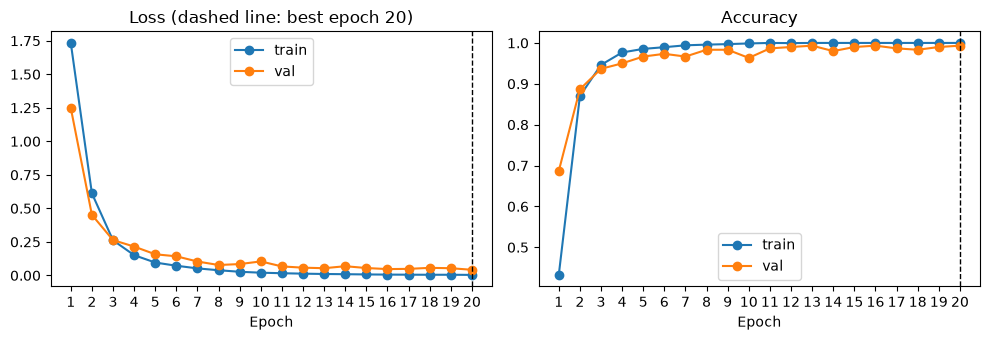

In [102]:
epochs = range(1, NUM_EPOCHS + 1)
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10, 3.5))
for split in ("train", "val"):
    losses, accs = zip(*history[split])
    ax_loss.plot(epochs, losses, marker="o", label=split)
    ax_acc.plot(epochs, accs, marker="o", label=split)
ax_loss.set_title(f"Loss (dashed line: best epoch {best_epoch})")
ax_acc.set_title("Accuracy")
for ax in (ax_loss, ax_acc):
    ax.axvline(best_epoch, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epochs))
    ax.legend()
fig.tight_layout()
plt.show()

**Discussion.** The CNN (about 33k parameters) reaches about 97% validation accuracy within 6 epochs and 98–99% by the end. Training accuracy reaches 100%, but validation loss keeps falling too, so the model isn't overfitting badly. The exact numbers vary slightly between CPU, CUDA and MPS. (Training accuracy is averaged over each epoch while the weights are still changing, which is why it can start below validation accuracy.)

The CNN can use the temporal structure that the averaged features throw away. Its convolutions pick up local time–frequency patterns such as formant transitions and onsets. Because the final layer works on the flattened feature map and not on an average, it also knows *roughly when* each pattern happens. That means it can tell apart words that share sounds in a different order, which a bag of averaged frames can't.

### 1D CNN

The 2D CNN treats the spectrogram as an ordinary image: square kernels and pooling, sliding along both time and frequency. An alternative common in speech models is to treat the 40 mel bands as **channels** and convolve only along time. Each filter then spans all frequencies at once and covers 5 frames (50 ms). It takes the same `[B, 1, 40, T]` input, reshaped to `[B, 40, T]`, and has the same three blocks of convolution, batch norm, ReLU and pooling.

In [103]:
def conv_block_1d(c_in, c_out):
    return [nn.Conv1d(c_in, c_out, kernel_size=5, padding=2), nn.BatchNorm1d(c_out), nn.ReLU(), nn.MaxPool1d(2)]


def make_cnn_1d():
    return nn.Sequential(
        nn.Flatten(start_dim=1, end_dim=2),  # [B, 1, 40, T] -> [B, 40, T]
        *conv_block_1d(N_MELS, 32),  # [32, 50]
        *conv_block_1d(32, 32),      # [32, 25]
        *conv_block_1d(32, 32),      # [32, 12]
        nn.Flatten(),
        nn.Linear(32 * 12, 10),
    ).to(device)


print(f"Parameters: {sum(p.numel() for p in make_cnn_1d().parameters()):,}")

runs_1d = [train_cnn(seed, make_model=make_cnn_1d, verbose=seed == SEEDS[0]) for seed in SEEDS]
cnn_1d = runs_1d[0][0]
print(val_summary(runs_1d))

Parameters: 20,778
Epoch 1: train loss 1.522, acc 0.537 | val loss 1.153, acc 0.707
Epoch 2: train loss 0.623, acc 0.884 | val loss 0.513, acc 0.887
Epoch 3: train loss 0.303, acc 0.946 | val loss 0.345, acc 0.903
Epoch 4: train loss 0.193, acc 0.968 | val loss 0.256, acc 0.913
Epoch 5: train loss 0.140, acc 0.976 | val loss 0.263, acc 0.910
Epoch 6: train loss 0.100, acc 0.985 | val loss 0.187, acc 0.937
Epoch 7: train loss 0.075, acc 0.989 | val loss 0.161, acc 0.960
Epoch 8: train loss 0.057, acc 0.993 | val loss 0.091, acc 0.983
Epoch 9: train loss 0.049, acc 0.994 | val loss 0.142, acc 0.960
Epoch 10: train loss 0.043, acc 0.995 | val loss 0.152, acc 0.957
Epoch 11: train loss 0.032, acc 0.996 | val loss 0.073, acc 0.987
Epoch 12: train loss 0.029, acc 0.997 | val loss 0.151, acc 0.943
Epoch 13: train loss 0.021, acc 0.997 | val loss 0.067, acc 0.977
Epoch 14: train loss 0.027, acc 0.995 | val loss 0.100, acc 0.980
Epoch 15: train loss 0.034, acc 0.992 | val loss 0.126, acc 0.953


**Discussion.** The 1D CNN does at least as well as the 2D CNN (about 99% validation accuracy, against 98%), with fewer parameters (21k against 33k) and about 4 times faster training. Letting every filter see all frequencies at once, at fixed positions, suits this data better than the 2D CNN's sliding along frequency. Its per-epoch validation accuracy is noisier, with occasional dips, so selecting the best-validation checkpoint matters more here.

## Part 4. Error analysis

Based on Part 3, the analysis uses the 1D CNN: it is at least as accurate as the 2D CNN while being smaller and faster. Errors are analysed on the validation set, using the first-seed 1D CNN.

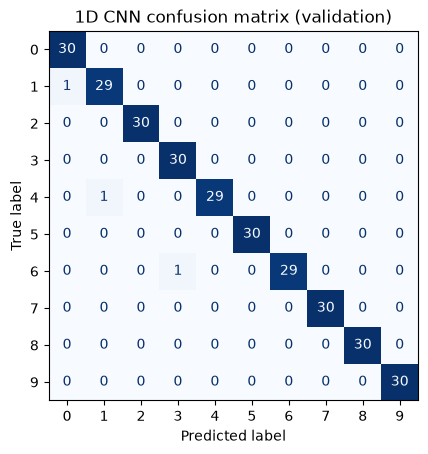

In [104]:
from sklearn.metrics import ConfusionMatrixDisplay

val_pred = predict(cnn_1d, features[val_mask])
ConfusionMatrixDisplay.from_predictions(y[is_val], val_pred, cmap="Blues", colorbar=False)
plt.title("1D CNN confusion matrix (validation)")
plt.show()

3 of 300 validation recordings misclassified:
  1_george_7.wav       true 1, predicted 0, 0.67 s
  4_nicolas_7.wav      true 4, predicted 1, 0.29 s
  6_nicolas_6.wav      true 6, predicted 3, 0.24 s


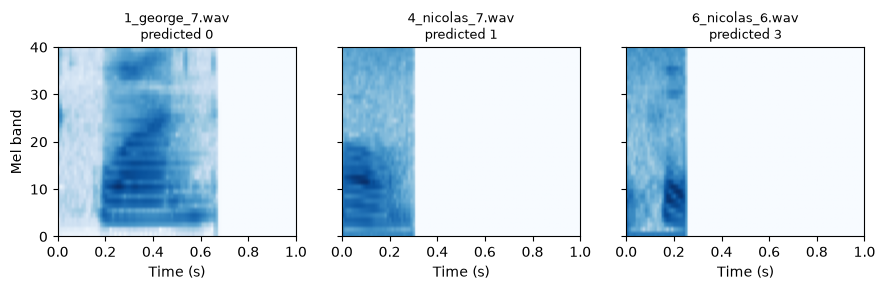

1_george_7.wav


4_nicolas_7.wav


6_nicolas_6.wav


In [105]:
from IPython.display import Audio, display

val_paths = [p for p, v in zip(paths, is_val) if v]
wrong = np.flatnonzero(val_pred != y[is_val])
print(f"{len(wrong)} of {len(val_paths)} validation recordings misclassified:")
for i in wrong:
    print(f"  {val_paths[i].name:<20} true {y[is_val][i]}, predicted {val_pred[i]}, {lengths[is_val][i] / SAMPLE_RATE:.2f} s")

shown = wrong[:4]
fig, axes = plt.subplots(1, len(shown), figsize=(3 * len(shown), 3), sharey=True, squeeze=False)
for ax, i in zip(axes[0], shown):
    ax.imshow(log_mels[val_mask][i], origin="lower", aspect="auto", cmap="Blues", extent=(0, 1, 0, N_MELS))
    ax.set_title(f"{val_paths[i].name}\npredicted {val_pred[i]}", fontsize=9)
    ax.set_xlabel("Time (s)")
axes[0, 0].set_ylabel("Mel band")
fig.tight_layout()
plt.show()

for i in shown:
    print(val_paths[i].name)
    display(Audio(waves[val_mask][i].numpy(), rate=SAMPLE_RATE))

**Observations.** The 1D CNN makes very few validation errors, and there is no systematic confusion between any pair of digits. The misclassified recordings are unusual:

- **Late start.** `1_george_7.wav` begins about 0.2 s into the clip, after silence. Most recordings start at t = 0, but some don't. Lucas, for example, starts after 0.1 s in about two thirds of his recordings.
- **Very short words.** `4_nicolas_7.wav` and `6_nicolas_6.wav` last only 0.24–0.29 s. Nicolas is the fastest speaker, with a median duration of about 0.35 s, so these clips have few frames for the model to work with.

So the remaining errors are edge cases (unusual timing or speaking rate), not a systematic weakness on particular digits.

## Test set comparison

Each model is evaluated once on the official test set (index 0–4, 300 recordings): the logistic regressions from Part 2 and the 2D and 1D CNNs from Part 3. Each CNN is its best-validation checkpoint, reported as mean ± std over 3 seeds. Validation accuracy is shown alongside for reference.

In [106]:
def mean_std(values):
    return f"{np.mean(values):.3f} ± {np.std(values):.3f}"


print(f"{'Model':<18}{'Params':>8}{'Val acc':>16}{'Test acc':>16}{'Test F1':>16}")
for name, X in feature_sets.items():
    clf = logregs[name]
    val_acc, _ = scores(y[is_val], clf.predict(X[is_val]))
    test_acc, test_f1 = scores(y[is_test], clf.predict(X[is_test]))
    params = clf[-1].coef_.size + clf[-1].intercept_.size
    print(f"{f'LogReg ({name})':<18}{params:>8,}{val_acc:>16.3f}{test_acc:>16.3f}{test_f1:>16.3f}")

for name, model_runs in {"2D CNN": runs_2d, "1D CNN": runs_1d}.items():
    val_accs = [h["val"][e - 1][1] for _, h, e in model_runs]
    test_accs, test_f1s = zip(*(scores(y[is_test], predict(m, features[test_mask])) for m, _, _ in model_runs))
    params = sum(p.numel() for p in model_runs[0][0].parameters())
    print(f"{name:<18}{params:>8,}{mean_std(val_accs):>16}{mean_std(test_accs):>16}{mean_std(test_f1s):>16}")
print(f"{'Random guessing':<18}{'':>8}{0.1:>16.3f}{0.1:>16.3f}{0.1:>16.3f}")

Model               Params         Val acc        Test acc         Test F1
LogReg (padded)        810           0.943           0.940           0.940
LogReg (trimmed)       810           0.970           0.950           0.950
LogReg (both)        1,610           0.983           0.960           0.960
2D CNN              33,418   0.986 ± 0.007   0.987 ± 0.005   0.987 ± 0.005
1D CNN              20,778   0.990 ± 0.003   0.992 ± 0.004   0.992 ± 0.004
Random guessing                      0.100           0.100           0.100


**Discussion.** Both CNNs beat the logistic regressions on the test set. The 1D CNN does best (about 99%), then the 2D CNN (about 98%), then the best logistic regression (**both**, 96%) and the original 80-feature baseline (**padded**, 94%). The seed-to-seed spread (±0.5%) is smaller than the gap between the CNNs and logistic regression, so that advantage is real on this split. It fits the idea that keeping temporal structure helps. The gap between the two CNNs is only 2–3 recordings, so the safe claim is that the smaller, faster 1D CNN is at least as good.

Validation and test agree closely for the CNNs. For logistic regression, test accuracy is 1–2 points below validation.

All of these numbers are for speakers seen during training, since every speaker appears in all three splits. Recognising digits from new speakers would be harder.